In [1]:
import requests
import json
import pandas as pd
import numpy as np
import os
from datetime import datetime

with open("keys.json") as f:
    data = json.loads(f.read())
    STEAM_DATA_API = data["STEAM_DATA_API"] 
    STEAM_WEB_API = data["STEAM_WEB_API"] 

BASE_URL = "https://www.steamwebapi.com/steam/"
DT_ISO8601_FORMAT = "%Y-%m-%d %H:%M:%S"

In [ ]:
def call(method: str, call_path: str, extra_params: str | None = None, payload: dict | None = None, base_url = BASE_URL):
    """
    calls the Steam Web API, stores the response to /data/steam_web_api, returns (location of saved file, errorcode)
    """
    method = method.upper()
    body = ""
    headers = {}

    request_url = base_url + call_path + "?key=" + STEAM_WEB_API 

    output_path = f"data/steam_web_api/{call_path.replace('/', '_')}"
    output_path = output_path[:output_path.find("markets")].rstrip()

    if extra_params != None:
        request_url = request_url + "&" + extra_params
        output_path = output_path + "_" + extra_params + "_" + str(datetime.now()) + ".json"

    if payload:
        body = json.dumps(payload)


    if method != "GET" and payload:
        headers["Content-Type"] = "application/json"

    try:
        r = requests.request(
            method,
            request_url,
            headers=headers,
            data=body.encode() if body else None,
            timeout=15,
        )
        r.raise_for_status()
        data_json = r.json()

        if len(data_json) == 0:
            return output_path, "RESPONSE EMPTY"
        
        with open(output_path, "x") as f:
            json.dump(data_json, f, indent=4)

        return output_path, None
    except requests.RequestException as e:
        detail = e.response.text if e.response is not None else "no body"
        return output_path, f"{e} — {detail}"


def getJsonFileasFlatMappedDataFrame(file_path):
    return pd.json_normalize(json.loads(open(file_path).read()))

def getJsonObjAsFlatMappedDataFrame(object):
    return pd.json_normalize(object)

def getData(call_name: str, file_name: str):
    """
    calls the Steam Data API, stores the response to /data/steam_data_api, returns (location of saved file, errorcode)
    """
    headers = {
        "Authorization": f"Bearer {STEAM_DATA_API}",
    }

    try:
        response = requests.get(
            call_name,
            headers=headers,
        )

        response.raise_for_status()
        data = response.json()
        file_name = file_name + "_" + str(datetime.now()) + ".json"
        with open(file_name, "x") as f:
            json.dump(data,f, indent=4)

        print(f"File: {file_name}" +  ", Size: " + str(os.path.getsize(file_name)/1000) + "KB" )
        return 0
    
    except requests.RequestException as e:
        detail = e.response.text if e.response is not None else "no body"
        print(f"{e} — {detail}")
        return 1

def getHistory(game: str = "cs2", days: int = 30, names: list = ["AK-47 | Redline (Field-Tested)"], file_name: str = "data/steam_data_api/history"):
    """
    calls the Steam Data API, stores the response to /data/steam_data_api, returns (location of saved file, errorcode)
    """
    headers = {
        "Authorization": f"Bearer {STEAM_DATA_API}",
        "Content-Type": "application/json"
    }

    try:
        response = requests.post(
            "https://steamdataapi.com/api/v1/items/history",
            headers=headers,
            json={
                "game": game,
                "days": days,
                "names": names
            }
        )

        response.raise_for_status()
        data = response.json()
        file_name = file_name + "_" + str(days) + "_" + str(datetime.now()) + ".json"
        with open(file_name, "x") as f:
            json.dump(data,f, indent=4)

        print(f"File: {file_name}" +  ", Size: " + str(os.path.getsize(file_name)/1000) + "KB" )
        return 0
    
    except requests.RequestException as e:
        detail = e.response.text if e.response is not None else "no body"
        print(f"{e} — {detail}")
        return 1


# API Aufrufe

In [26]:
call_path = "api/items"
game_param = "game=cs2"

full_params = game_param + '&' + 'page=0'
location, errorcode = call("GET", call_path, full_params)
if (errorcode != None):
    print(errorcode)
print(f"File: {location}" +  ", Size: " + str(os.path.getsize(location)/1000) + "KB")


File: data/steam_web_api/api_item_game=cs2&page=0_2026-11-20 14:14:36.569459.json, Size: 421525.49KB


In [31]:
call_path = "https://steamdataapi.com/api/v1/items/all?game=cs2&markets=1&variants=1&currency=USD"
file_name = "data/steam_data_api/all_items_"

errorcode = getData(call_path, file_name)

File: data/steam_data_api/all_items__2026-11-24 06:57:25.507588.json, Size: 132686.874KB


In [ ]:
weapons = []




In [30]:
from time import sleep

for pageNum in range(1,62):
    call_path = f"https://steamdataapi.com/api/v1/buy-orders?game=cs2&limit=500&page={pageNum}&currency=USD"
    file_name = f"data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_{pageNum}"
    errorcode = getData(call_path, file_name)
    sleep(2)
    if errorcode == 1:
        break

File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_1_2026-11-24 06:54:53.461498.json, Size: 1261.025KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_2_2026-11-24 06:54:55.954354.json, Size: 1291.162KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_3_2026-11-24 06:54:58.415537.json, Size: 1273.798KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_4_2026-11-24 06:55:00.842304.json, Size: 1256.387KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_5_2026-11-24 06:55:03.266095.json, Size: 1243.569KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_6_2026-11-24 06:55:05.798281.json, Size: 1222.061KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_7_2026-11-24 06:55:08.254800.json, Size: 1269.971KB
File: data/steam_data_api/buy_orders_2026-11-24 07:54/buy_orders_page_8_2026-11-24 06:55:10.705879.json, Size: 1266.063KB
File: data/steam_data_ap

# Datenexploration der Verkaufsangebote

In [4]:
def remove_0_prices(df: pd.DataFrame):
    """
    Aufgrund von abrundung werden manche preise > 1 cent als 0 zurückgegeben
    -> bei kauf würden diese aber auf 1 cent aufgerundet werden
    """
    df.loc[df["price"] == 0, 'price'] = 1

def organize_columns(df: pd.DataFrame):
    """
    Löschen von unnötigen Spalten & umbenennung
    """
    df = df[["marketHashName","sold24h","markets","variants"]]
    df = df.rename(columns={"sold24h":"steam_sales_last_24h"})
    return df

def add_captured_at_to_variants_df(df: pd.DataFrame):
    df = df.explode("markets").dropna(subset=["markets"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["markets"])
    variant_cols = "capturedAt"
    return pd.concat([df.drop(columns=["markets"]), market_details[variant_cols]], axis=1).drop_duplicates(subset="marketHashName")


def divide_df_based_on_variants(df: pd.DataFrame):
    """
    Trennt items in zwei dataframes, eins enthält json object mit variants informationen, anderes enthält keine variants 
    """
    has_variants = df["variants"].notna() & (df["variants"].str.len() > 0)
    df_no_var = df[~has_variants].drop(columns=["variants"])
    df_no_var["variant"] = "N"

    df_var = df[has_variants]
    df_var = add_captured_at_to_variants_df(df_var)

    return df_no_var, df_var


def extract_variants(df: pd.DataFrame):
    """
    json objekt in variants spalte wird exploded & normalisiert -> eine zeile pro variante
    """
    df = df.explode("variants").reset_index(drop=True)
    variant_details = pd.json_normalize(df["variants"])
    variant_cols = [c for c in ["variant", "markets"] if c in variant_details.columns]
    return pd.concat([df.drop(columns=["variants"]), variant_details[variant_cols]], axis=1)

def extract_markets(df: pd.DataFrame):
    """
    markt dictionaries in markets spalte werden exploded & normalisiert -> eine zeile pro markt, da es unterschiedliche namensgebungen zwischen den varianten markets und den no_variant markets gibt, werden die namen normalisiert (updatedAt / capturedAt -> capturedAt)
    """
    df = df.explode("markets").dropna(subset=["markets"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["markets"])
    return pd.concat(
        [
            df.drop(columns=["markets"]),
            market_details.drop(columns=["icon", "updatedAt"], errors="ignore"),
        ],
        axis=1,
    )

def normalize_sell_orders(df: pd.DataFrame):
    """
    1. schauen ob varianten existieren oder nicht
    2. wenn varianten existieren, exploden & normalisieren, jede variante hat wieder eigene markets liste
    3. varianten namen umbennen, da quantityUpdatedAt / updatedAt/capturedAt nicht gleich genannt werden 
    4. alle zusammenfügen & market exploden & normalisieren
    """
    df = organize_columns(df)

    df_no_var, df_var = divide_df_based_on_variants(df)

    df_no_var = extract_markets(df_no_var)

    if not df_var.empty:
        df_var = extract_variants(df_var)
        df_var = extract_markets(df_var)

        combined_df = pd.concat([df_no_var, df_var], ignore_index=True)
    else:
        combined_df = df_no_var.reset_index(drop=True)

    remove_0_prices(combined_df)
    combined_df["capturedAt"] = pd.to_datetime(combined_df["capturedAt"], format='ISO8601', utc=True)  
    combined_df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return combined_df


def normalize_sell_orders_drop_variants(df: pd.DataFrame):
    df = organize_columns(df)

    has_variants = df["variants"].notna() & (df["variants"].str.len() > 0)
    df = df[~has_variants].drop(columns=["variants"])
    df = extract_markets(df)
    remove_0_prices(df)
    df["capturedAt"] = pd.to_datetime(df["capturedAt"], format='ISO8601', utc=True)  
    df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return df
       

In [ ]:
all_items_file_alt = json.loads(open("data/steam_data_api/all_items_no_info_2026-11-17 13:44:47.776898.json").read())
verkaufs_angebote_alt = getJsonObjAsFlatMappedDataFrame(all_items_file_alt["data"])

all_items_file_neu = json.loads(open("data/steam_data_api/all_items_no_info_2026-11-17 18:05:45.603960.json").read())
verkaufs_angebote_neu = getJsonObjAsFlatMappedDataFrame(all_items_file_neu["data"])

verkaufs_angebote_alt = normalize_sell_orders(verkaufs_angebote_alt)
verkaufs_angebote_neu = normalize_sell_orders(verkaufs_angebote_neu)

In [49]:
dt_verkaufs_angebote_alt = "2026-11-17 13:44:47"
dt_verkaufs_angebote_neu = "2026-11-17 18:05:45"

dt_verkaufs_angebote_alt = pd.to_datetime(datetime.strptime(dt_verkaufs_angebote_alt, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 
dt_verkaufs_angebote_neu = pd.to_datetime(datetime.strptime(dt_verkaufs_angebote_neu, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 

In [50]:
verkaufs_angebote_alt.head()

,marketHashName,steam_sales_last_24h,variant,market,price,quantity,capturedAt,priceUpdatedAt
0,'Blueberries' Buckshot | NSWC SEAL,17.0,N,avan,936,216.0,2026-11-17 13:43:09.578000+00:00,2026-11-20 15:25:50.707754+00:00
1,'Blueberries' Buckshot | NSWC SEAL,17.0,N,buff163,897,187.0,2026-11-17 13:44:25.468000+00:00,2026-11-20 15:25:50.707754+00:00
2,'Blueberries' Buckshot | NSWC SEAL,17.0,N,c5game,926,263.0,2026-11-17 13:44:25.468000+00:00,2026-11-20 15:25:50.707754+00:00
3,'Blueberries' Buckshot | NSWC SEAL,17.0,N,csfloat,930,190.0,2026-11-17 13:40:20.942000+00:00,2026-11-20 15:25:50.707754+00:00
4,'Blueberries' Buckshot | NSWC SEAL,17.0,N,csmoney,909,95.0,2026-11-17 13:44:01.373000+00:00,2026-11-20 15:25:50.707754+00:00


# 1. Vollständigkeit 

-> Wie viele einzigartige Skin+varianten haben Verkaufsangebote auf mehr als einem Markt

In [37]:
unique_columns = ["marketHashName", "variant", "market"]

# 1. Alle möglichen Zeilen
print(f"Count verkaufs_angebote_alt: {verkaufs_angebote_alt.shape[0]}")
print(f"Count verkaufs_angebote_neu: {verkaufs_angebote_neu.shape[0]} \n")

#2. Einzigarte Entries (name + variante + markt)
print(f"Count Angebote ohne Duplikate alt: {verkaufs_angebote_alt[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Angebote ohne Duplikate neu: {verkaufs_angebote_neu[unique_columns].drop_duplicates().shape[0]} \n")

#3. Insgesamt alle möglichen skin + variant möglichkeiten
unique_columns = ["marketHashName", "variant"]
print(f"Count Alle skin+variant möglichkeiten alt: {verkaufs_angebote_alt[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Alle skin+variant möglichkeiten neu: {verkaufs_angebote_neu[unique_columns].drop_duplicates().shape[0]} \n")

#3. Skin + variant möglichkeiten, mit Angeboten auf mind 2 platformen
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: {(verkaufs_angebote_alt.groupby(unique_columns)['market'].nunique() >= 2).value_counts()}")
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: {(verkaufs_angebote_neu.groupby(unique_columns)['market'].nunique() >= 2).value_counts()}")

Count verkaufs_angebote_alt: 392998
Count verkaufs_angebote_neu: 392415 

Count Angebote ohne Duplikate alt: 392998
Count Angebote ohne Duplikate neu: 392415 

Count Alle skin+variant möglichkeiten alt: 31807
Count Alle skin+variant möglichkeiten neu: 31809 

Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: market
True     30763
False     1044
Name: count, dtype: int64
Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: market
True     30759
False     1050
Name: count, dtype: int64


# 2. Eindeutingkeit
Gibt es duplikate für einen Eintrag ? (HashName + Variante + Markt)

In [52]:
subset_cols  = ['marketHashName', 'variant', 'market']

print(f" Duplizierte Einträge alt: {verkaufs_angebote_alt.duplicated(subset=subset_cols).sum()}")
print(f" Duplizierte Einträge neu: {verkaufs_angebote_neu.duplicated(subset=subset_cols).sum()}")

 Duplizierte Einträge alt: 0
 Duplizierte Einträge neu: 0


# 3. Plausibilität 

Wo liegen die Preisunterschiede? 
-> CS Markt sehr Volatil, also vergleich mit einer anderen Aggregator API

In [53]:
def extract_prices(df: pd.DataFrame):
    df = df.explode("prices").dropna(subset=["prices"]).reset_index(drop=True)
    price_details = pd.json_normalize(df["prices"], max_level=0)
    price_cols = [c for c in ["price", "source", "quantity", "type", "created_at", "variants"] if c in price_details.columns]
    return pd.concat([df.drop(columns=["prices"]), price_details[price_cols]], axis=1)

def extract_variants(df: pd.DataFrame):
    df = df.drop(columns=["price"])
    exploded = df.assign(variants=df["variants"].apply(lambda d: list(d.items()) if isinstance(d, dict) else [])).explode("variants")
    exploded[["variant", "price"]] = pd.DataFrame(exploded["variants"].tolist(), index=exploded.index)
    return exploded.drop(columns=["variants"])

def normalize_web_api_items(df: pd.DataFrame):
    df = df[["markethashname", "priceupdatedat.date", "prices"]]
    df = df.rename(columns={"priceupdatedat.date": "priceupdatedat"})
    has_info = (df["prices"].notna() & (df["prices"].str.len() > 0) & df["priceupdatedat"].notna())
    df = df[has_info]
    
    df = extract_prices(df)

    has_variants = df["variants"].notna()
    no_var = df[~has_variants]
    var = df[has_variants]

    no_var = no_var.drop(columns=["variants"])
    no_var["variant"] = "N"
    
    if not var.empty:
        var = extract_variants(var)
        combined_df = pd.concat([no_var, var], ignore_index=True)
    else:
        combined_df = no_var.reset_index(drop=True)

    remove_0_prices(combined_df)
    combined_df["created_at"] = pd.to_datetime(combined_df["created_at"], format='ISO8601', utc=True)    
    combined_df["priceupdatedat"] = pd.to_datetime(combined_df["priceupdatedat"], format='ISO8601', utc=True)  
    
    combined_df = combined_df.rename(columns={"priceupdatedat": "capturedAt", "created_at": "order_created_at", "markethashname": "marketHashName", "source": "market"})
    combined_df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return combined_df

In [58]:
# Neue API daten verwenden, da Zeitunterschied von mehreren Stunden für grosse Preisunterschied gesorgt hat 

data_api_file = json.loads(open("data/steam_data_api/all_items__2026-11-20 14:15:58.061678.json").read())
data_api_items = getJsonObjAsFlatMappedDataFrame(data_api_file["data"])
data_api_items = normalize_sell_orders(data_api_items)

In [59]:
def get_aggregated_price_info(df: pd.DataFrame)-> pd.DataFrame:
     # Group pro item & Aggregate Prices, also build interesting statistical values
     price_stats = (df
                    .groupby(["marketHashName", "variant"], dropna=False)['price']
                    .agg(market_count = 'count',
                         min_price = 'min',
                         median_price = 'median',
                         max_price = 'max',
                         std_price = 'std').reset_index())


     price_stats['abs_spread'] = price_stats['max_price'] - price_stats['min_price']
     price_stats['rel_spread_pct'] = (price_stats['abs_spread'] / price_stats['min_price']) * 100
     price_stats['extreme_spreads'] = (price_stats['rel_spread_pct'] > 100)

     price_stats = price_stats[price_stats["market_count"] >= 2]
     return price_stats

In [60]:
price_stats = get_aggregated_price_info(data_api_items)
extreme_spreads = price_stats[price_stats['extreme_spreads']]
print(f"Items with spread between Platforms over 100% {extreme_spreads.shape[0]}")
print(f"Items without Spread: {price_stats[price_stats['rel_spread_pct'] <= 0].shape[0]}")
print(f"Average Spread across all items: {price_stats['rel_spread_pct'].sum() / price_stats['rel_spread_pct'].shape[0]}")  
print(f"Average Spread across all items: {price_stats['rel_spread_pct'].sum() / price_stats['rel_spread_pct'].shape[0]}")  
price_stats.describe()

Items with spread between Platforms over 100% 15466
Items without Spread: 14
Average Spread across all items: 139.61910194619995
Average Spread across all items: 139.61910194619995


,market_count,min_price,median_price,max_price,std_price,abs_spread,rel_spread_pct
count,30774.000000,3.077400e+04,3.077400e+04,3.077400e+04,3.077400e+04,3.077400e+04,30774.000000
mean,12.749691,9.444507e+03,1.129060e+04,1.558826e+04,2.174433e+03,6.143756e+03,139.619102
std,3.703593,8.773961e+04,1.234522e+05,1.445273e+05,3.301115e+04,6.697426e+04,113.244517
min,2.000000,1.000000e+00,1.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,11.000000,2.700000e+01,3.500000e+01,5.900000e+01,7.855029e+00,2.700000e+01,41.246947
50%,14.000000,2.405000e+02,3.070000e+02,5.010000e+02,6.360580e+01,2.140000e+02,101.447619
75%,16.000000,2.939000e+03,3.644500e+03,5.216750e+03,5.398065e+02,1.765000e+03,223.173368
max,16.000000,7.499963e+06,1.499992e+07,1.511806e+07,4.547565e+06,8.443097e+06,400.000000


## Pretty big spreads, compare with data from other source (steam web api)

In [61]:
web_api_file = json.loads(open("data/steam_web_api/api_item_game=cs2&page=0_2026-11-20 14:14:36.569459.json").read())
web_api_items = getJsonObjAsFlatMappedDataFrame(web_api_file) 
web_api_items = normalize_web_api_items(web_api_items)

In [62]:
alternative_price_stats = get_aggregated_price_info(web_api_items)
extreme_spreads = alternative_price_stats[alternative_price_stats['extreme_spreads']]
print(f"Items with spread between Platforms over 100% {extreme_spreads.shape[0]}")
print(f"Items without Spread: {alternative_price_stats[alternative_price_stats['rel_spread_pct'] <= 0].shape[0]}")
print(f"Average Spread across all items: {alternative_price_stats['rel_spread_pct'].sum() / alternative_price_stats['rel_spread_pct'].shape[0]}")  
alternative_price_stats.describe()

Items with spread between Platforms over 100% 21082
Items without Spread: 2
Average Spread across all items: 1312.3801649787604


,market_count,min_price,median_price,max_price,std_price,abs_spread,rel_spread_pct
count,33662.000000,33662.000000,33662.000000,33662.000000,33662.000000,33662.000000,33662.000000
mean,10.817747,68.606390,83.703363,139.730382,26.537346,71.123992,1312.380165
std,3.881174,783.068808,1110.115339,1341.519606,332.300764,740.488952,6532.474984
min,2.000000,0.010000,0.010000,0.020000,0.000000,0.000000,0.000000
25%,9.000000,0.340000,0.530000,1.960000,0.324274,0.990000,52.173913
50%,12.000000,2.380000,3.327500,10.550000,1.767091,5.410000,200.000000
75%,14.000000,19.570000,25.751250,51.022500,8.046515,24.630000,853.804234
max,57.000000,74835.890000,149671.770000,156963.540000,46786.027992,90293.380000,349900.000000


## Ergebnis: Gleich große Unterschiede / Extreme 

1. Kleine centbeträge verändern spread extrem (1 cent vs 3 cent unterschied = 200% spread)

2. Vergleich von Min und Max macht relativ wenig sinn.

Da es sind liegende Angebote sind, also Max preis kann deutlich überzogen sein.

# Claude Vergleich

In [63]:
norm = lambda s: s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
web_api_items.loc[web_api_items["market"] == "buff", 'market'] = "buff163"

main = data_api_items.assign(mp=norm(data_api_items["market"]))
alt  = web_api_items.assign(mp=norm(web_api_items["market"]))

pm, pa = set(main["mp"]), set(alt["mp"])
common = pm & pa
print(len(pm), len(pa), len(common))
print("only main:", sorted(pm - pa))
print("only alt:", sorted(pa - pm))

sm = get_aggregated_price_info(main[main["mp"].isin(common)])
sa = get_aggregated_price_info(alt[alt["mp"].isin(common)])
print(sm["rel_spread_pct"].describe())
print(sa["rel_spread_pct"].describe())

# 2) where does the alt maximum come from?
g = ["marketHashName", "variant"]
top = alt.loc[alt.groupby(g, dropna=False)["price"].idxmax()]
print(top["mp"].value_counts().head(10))
print("share of alt maxima from platforms the main data also has:", top["mp"].isin(pm).mean())

16 16 9
only main: ['avan', 'c5game', 'csmoney', 'csmoneytrade', 'mannco', 'marketcsgo', 'whitemarket']
only alt: ['49skins', 'csdeals', 'csgocom', 'skinflow', 'skinland', 'skinscom', 'tradeit']
count    30456.000000
mean       116.496676
std        103.313062
min          0.000000
25%         32.256929
50%         79.310345
75%        184.730475
max        400.000000
Name: rel_spread_pct, dtype: float64
count     33470.000000
mean        896.877247
std        4829.689981
min           0.000000
25%          35.341075
50%         114.516129
75%         533.765574
max      230600.000000
Name: rel_spread_pct, dtype: float64
mp
skinflow     6066
csgocom      3485
skinport     3214
skinbaron    3174
dmarket      2802
skinland     2344
skinscom     2267
youpin       1981
tradeit      1816
buff163      1795
Name: count, dtype: int64
share of alt maxima from platforms the main data also has: 0.48903692976104274


In [64]:
ck = ["marketHashName", "variant"]

# A) item-level: items present in both sources, shared platforms only
sm_ = sm.assign(variant=sm["variant"].fillna(""))
sa_ = sa.assign(variant=sa["variant"].fillna(""))
c = sm_.merge(sa_, on=ck, suffixes=("_main", "_alt"))
print(len(sm), len(sa), len(c))
print(c[["rel_spread_pct_main", "rel_spread_pct_alt"]].describe())
print("same platform count:", (c["market_count_main"] == c["market_count_alt"]).mean())
c["min_ratio"] = c["min_price_main"] / 100 / c["min_price_alt"]
c["max_ratio"] = c["max_price_main"] / 100 / c["max_price_alt"]
print(c[["min_ratio", "max_ratio"]].describe())

# B) listing-level: does alt have listings that main lacks, on the same item + platform?
k = ["marketHashName", "variant", "mp"]
m_ = main.assign(variant=main["variant"].fillna(""), usd=main["price"] / 100)
a_ = alt.assign(variant=alt["variant"].fillna(""), usd=alt["price"])
items_main = m_[ck].drop_duplicates()
a_sh = a_[a_["mp"].isin(common)].merge(items_main, on=ck)           # alt, shared platforms, items main knows
chk = a_sh.merge(m_[k].drop_duplicates(), on=k, how="left", indicator=True)
print("alt listings missing in main:", (chk["_merge"] == "left_only").mean())

j = m_[k + ["usd"]].merge(a_[k + ["usd"]], on=k, suffixes=("_main", "_alt"))
j["ratio"] = j["usd_main"] / j["usd_alt"]
print(len(j), "pairs | within 1 cent:", ((j["usd_main"] - j["usd_alt"]).abs() <= 0.011).mean(),
      "| within 5%:", ((j["ratio"] - 1).abs() < .05).mean())
print(j.groupby("mp")["ratio"].agg(["count", "median", lambda s: (s.sub(1).abs() < .05).mean()]))

30456 33470 29547
       rel_spread_pct_main  rel_spread_pct_alt
count         29547.000000        29547.000000
mean            118.229955          917.034023
std             103.697732         5015.160552
min               0.000000            0.000000
25%              33.333333           36.231884
50%              81.037349          110.884354
75%             188.888889          522.660293
max             400.000000       230600.000000
same platform count: 0.6704572376214167
          min_ratio     max_ratio
count  29547.000000  29547.000000
mean       0.999144      0.771070
std        0.041752      0.370851
min        0.214286      0.001300
25%        1.000000      0.384615
50%        1.000000      1.000000
75%        1.000000      1.000000
max        2.000000      4.534694
alt listings missing in main: 0.062307715939662854
213656 pairs | within 1 cent: 0.8740779570899015 | within 5%: 0.9903208896543977
           count  median  <lambda_0>
mp                                  
buff163

In [65]:
# Test 1: are the listings main lacks the extreme ones?
# (needs: m_, a_, k, ck, items_main, common from the earlier code)
med = a_.groupby(ck)["usd"].median().rename("med").reset_index()
chk = (a_[a_["mp"].isin(common)].merge(items_main, on=ck)
         .merge(m_[k].drop_duplicates(), on=k, how="left", indicator=True)
         .merge(med, on=ck))
chk["rel"] = chk["usd"] / chk["med"]
print(chk.groupby("_merge")["rel"].describe(percentiles=[.01, .05, .5, .95, .99]))

# Does main bound its own listings relative to the item median?
m_["rel"] = m_["usd"] / m_.groupby(ck)["usd"].transform("median")
print(m_["rel"].describe(percentiles=[.001, .01, .99, .999]))

# Test 2: spread on matched listings only
g = j.groupby(ck)
cmp_ = pd.DataFrame({"n": g.size(),
                     "spr_main": (g["usd_main"].max() / g["usd_main"].min() - 1) * 100,
                     "spr_alt":  (g["usd_alt"].max()  / g["usd_alt"].min()  - 1) * 100})
cmp_ = cmp_[cmp_["n"] >= 2]
print(cmp_[["spr_main", "spr_alt"]].describe(percentiles=[.5, .75, .95, .99]))
print("alt spread > 400% on matched listings:", (cmp_["spr_alt"] > 400).mean())

# Test 3: CNY platforms and rounding
j["ok1c"] = (j["usd_main"] - j["usd_alt"]).abs() <= 0.011
print(j.groupby("mp")["ok1c"].mean().sort_values())

/tmp/ipykernel_1037/566428702.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(chk.groupby("_merge")["rel"].describe(percentiles=[.01, .05, .5, .95, .99]))


               count      mean        std       min        1%   5%       50%  \
_merge                                                                         
left_only    14197.0  8.959384  26.619306  0.046296  0.781047  1.0  4.547044   
right_only       0.0       NaN        NaN       NaN       NaN  NaN       NaN   
both        213656.0  1.016384   0.374220  0.004592  0.241192  0.5  0.989408   

                  95%        99%         max  
_merge                                        
left_only   24.419499  66.682500  875.000000  
right_only        NaN        NaN         NaN  
both         1.603094   2.639968   10.481326  
count    393382.000000
mean          1.064189
std           0.350927
min           0.200000
0.1%          0.333333
1%            0.500000
50%           1.000000
99%           2.652550
99.9%         3.898638
max           5.000000
Name: rel, dtype: float64
           spr_main       spr_alt
count  29521.000000  29521.000000
mean     117.449740    117.276006
std   

In [66]:
mmin = m_.groupby(ck)["usd"].min().rename("mmin").reset_index()
chk = chk.merge(mmin, on=ck)
chk["x_min"] = chk["usd"] / chk["mmin"]

lo = chk[chk["_merge"] == "left_only"]
print(lo["x_min"].describe(percentiles=[.001, .01, .05, .5]))
print("alt-only listings NOT beyond 5x:", (lo["x_min"] <= 5).mean())
print("largest ratio main keeps:", chk.loc[chk["_merge"] == "both", "x_min"].max())

# sensitivity: how much do spread statistics depend on the cut-off k?
for k in (3, 5, 10, 20, 50):
    f = a_[a_["usd"] <= k * a_.groupby(ck)["usd"].transform("min")]
    s = f.groupby(ck)["usd"].agg(n="count", lo="min", hi="max")
    s = s[s["n"] >= 2]
    print(k, len(s), ((s["hi"] / s["lo"] - 1) * 100).median())

count    14197.000000
mean        23.962877
std         74.457547
min          0.625000
0.1%         1.005562
1%           1.819692
5%           5.087294
50%         10.893238
max       2307.000000
Name: x_min, dtype: float64
alt-only listings NOT beyond 5x: 0.04176938789885187
largest ratio main keeps: 26.25
3 32939 79.99999999999999
5 33249 106.82093869553046
10 33470 149.88825079554493
20 33583 183.93574297188752
50 33636 198.67037755418164


In [67]:
# 1) what main itself keeps (its own prices); expect max = 5.0
m_["x_min"] = m_["usd"] / m_.groupby(ck)["usd"].transform("min")
print(m_["x_min"].describe(percentiles=[.99, .999]))
bo = chk[chk["_merge"] == "both"]
print((bo["x_min"] > 5).sum(), "of", len(bo), "shared rows differ strongly in price")

# 2) which k reproduces main's spread distribution best?
qs = [.25, .5, .75, .9]
print("main", price_stats["rel_spread_pct"].quantile(qs).round(1).tolist())
for k in (3, 4, 5, 6, 8):
    f = a_[a_["usd"] <= k * a_.groupby(ck)["usd"].transform("min")]
    s = f.groupby(ck)["usd"].agg(n="count", lo="min", hi="max")
    s = s[s["n"] >= 2]
    print(k, ((s["hi"] / s["lo"] - 1) * 100).quantile(qs).round(1).tolist())

# 3) the ~3,900 items only alt has (restricted to shared platforms): are they cheap?
only_alt = sa_.merge(sm_[ck], on=ck, how="left", indicator=True)
only_alt = only_alt[only_alt["_merge"] == "left_only"]
print(len(only_alt))
print(only_alt["min_price"].describe(percentiles=[.5, .9]))

count    393382.000000
mean          1.422745
std           0.657265
min           1.000000
50%           1.158985
99%           4.114046
99.9%         5.000000
max           5.000000
Name: x_min, dtype: float64
8 of 213656 shared rows differ strongly in price
main [41.2, 101.4, 223.2, 305.0]
3 [36.4, 80.0, 138.8, 189.7]
4 [40.0, 96.3, 191.1, 265.4]
5 [42.5, 106.8, 223.3, 312.5]
6 [44.4, 118.8, 267.6, 395.0]
8 [46.4, 135.6, 305.0, 508.9]
3923
count     3923.000000
mean        50.005088
std        316.645671
min          0.090000
50%          3.170000
90%         58.130000
max      15387.470000
Name: min_price, dtype: float64


In [68]:
nm = (m_[m_["mp"].isin(common)].groupby(ck).size().rename("n_main").reset_index())
oa = only_alt.merge(nm, on=ck, how="left")
print(oa["n_main"].value_counts(dropna=False).head())       # 1 = filter hypothesis, NaN = absent in main
print(oa["market_count"].value_counts().head())             # mostly 2?
print(oa["rel_spread_pct"].describe(percentiles=[.25, .5, .75]))
print("spread > 400%:", (oa["rel_spread_pct"] > 400).mean())

n_main
NaN    3771
1.0     152
Name: count, dtype: int64
market_count
3    1756
4     997
2     709
5     314
6      44
Name: count, dtype: int64
count      3923.000000
mean        745.061734
std        3090.351792
min           0.000000
25%          25.805556
50%         138.186158
75%         611.130192
max      100778.787879
Name: rel_spread_pct, dtype: float64
spread > 400%: 0.3178689778230946


## Verbesserung der Plausabilitätsabfrage (Claude)

In [69]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

CENT = 1

def robust_stats(df):
    """ Per item statistiken"""
    s = (df.groupby(["marketHashName", "variant"], dropna=False)["price"]
           .agg(n="count", min_p="min", max_p="max", med="median",
                q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75),
                second_min=lambda x: x.nsmallest(2).iloc[-1] if len(x) > 1 else np.nan)
           .reset_index())
    s["abs_spread"]  = s["max_p"] - s["min_p"]
    s["rel_pct"]     = s["abs_spread"] / s["min_p"] * 100                    # your current metric
    s["log_ratio"]   = np.log(s["max_p"] / s["min_p"])                       # scale-free
    s["sym_pct"]     = s["abs_spread"] / ((s["max_p"] + s["min_p"]) / 2) * 100  # bounded, symmetric
    s["med_pct"]     = s["abs_spread"] / s["med"] * 100                      # denominator = robust level
    s["iqr_pct"]     = (s["q3"] - s["q1"]) / s["med"] * 100                  # ignores outlier platforms
    s["gap12_pct"]   = (s["second_min"] - s["min_p"]) / s["min_p"] * 100     # lowest vs. second lowest
    # rounding: a 1-cent observed spread cannot be told apart from 0
    s["rounding_pct"] = CENT / s["min_p"] * 100                              # rounding-only spread bound
    s["resolvable"]   = s["abs_spread"] > CENT
    return s

def sim_median_spread(n, base, sigma=0.03, reps=5000):
    p = np.maximum(np.round(base * np.exp(rng.normal(0, sigma, (reps, n))), 2), CENT)
    return np.median((p.max(1) - p.min(1)) / p.min(1) * 100)

overall spearman: -0.22884856930315234
                       items  spearman_n  median_rel_pct  median_sym_pct  \
bucket                                                                     
(0.999, 18.0]         5408.0   -0.074186      288.888889      118.181818   
(18.0, 81.5]          5202.0   -0.480721      114.285714       72.727273   
(81.5, 351.0]         5296.0   -0.441113       91.068376       62.575243   
(351.0, 1617.5]       5298.0   -0.326797       92.476360       63.236799   
(1617.5, 9192.0]      5301.0   -0.008485       50.114286       40.073109   
(9192.0, 15000375.0]  5302.0    0.041294       36.575159       30.920536   

                      median_iqr_pct  share_resolvable  
bucket                                                  
(0.999, 18.0]              44.444444          0.995562  
(18.0, 81.5]               14.864865          0.997309  
(81.5, 351.0]              11.974139          0.992069  
(351.0, 1617.5]            12.361111          0.976784  
(1617.5, 9

/tmp/ipykernel_1037/1409851082.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({"items": len(d),


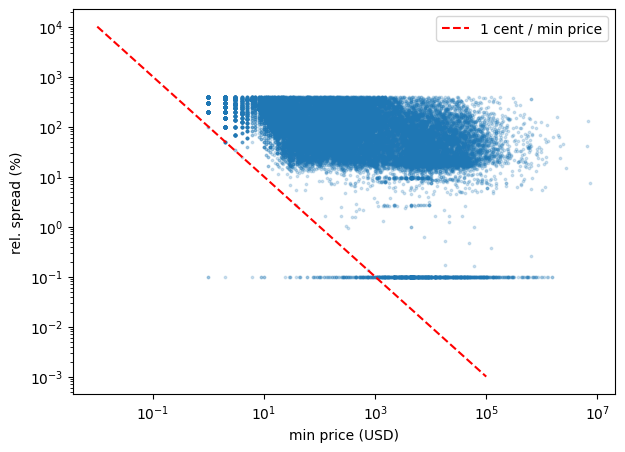

    0.03    0.50       5.00       50.00      500.00
3      0.0     0.0   4.878049   4.921907   4.847407
8      0.0     0.0   8.750000   8.785001   8.814280
12     0.0     0.0  10.041841  10.130060  10.148164
16     0.0     0.0  11.040340  11.023763  11.079817
items >= 1 USD: 18725 | share with sym_pct > band: 0.948090787716956 | share with iqr_pct > band: 0.3310013351134847


In [70]:


stats = robust_stats(verkaufs_angebote_alt)
print("overall spearman:", stats["rel_pct"].corr(stats["n"], method="spearman"))
stats["bucket"] = pd.qcut(stats["med"], 6, duplicates="drop")
print(stats.groupby("bucket", observed=True)
           .apply(lambda d: pd.Series({"items": len(d),
                                       "spearman_n": d["rel_pct"].corr(d["n"], method="spearman"),
                                       "median_rel_pct": d["rel_pct"].median(),
                                       "median_sym_pct": d["sym_pct"].median(),
                                       "median_iqr_pct": d["iqr_pct"].median(),
                                       "share_resolvable": d["resolvable"].mean()})))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(stats["min_p"], stats["rel_pct"].clip(lower=0.1), s=3, alpha=.2)
x = np.logspace(-2, 5, 200)
ax.plot(x, CENT / x * 100, "r--", label="1 cent / min price")
ax.set(xscale="log", yscale="log", xlabel="min price (USD)", ylabel="rel. spread (%)")
ax.legend(); plt.show()

rng = np.random.default_rng(0)


null = pd.DataFrame({base: [sim_median_spread(n, base) for n in (3, 8, 12, 16)]
                     for base in (0.03, 0.5, 5, 50, 500)}, index=[3, 8, 12, 16])
print(null)

FEE_BAND_PCT = 15   # placeholder: fill in from the platforms' fee tables
ok = stats[stats["resolvable"] & (stats["min_p"] >= CENT / 0.01)]   # rounding <= 1 %, i.e. min >= 1 USD
print("items >= 1 USD:", len(ok),
      "| share with sym_pct > band:", (ok["sym_pct"] > FEE_BAND_PCT).mean(),
      "| share with iqr_pct > band:", (ok["iqr_pct"] > FEE_BAND_PCT).mean())

# Vergleich 20 zufälliger Reihen mit Preisen auf Marktplatz-Website

In [18]:
import random 
items_meta_file = json.loads(open("data/steam_data_api/all_items_meta_2026-11-20 12:09:23.273499.json").read())
meta_orders = getJsonObjAsFlatMappedDataFrame(items_meta_file["data"])
newest_items = normalize_sell_orders(meta_orders)

In [25]:
random_numbers = random.sample(range(1, newest_items.index.max()), 20)


In [30]:
newest_items.iloc[random_numbers]

,marketHashName,steam_sales_last_24h,variant,market,price,quantity,capturedAt,priceUpdatedAt
40436,Glock-18 | Steel Disruption (Field-Tested),2.0,N,marketcsgo,897,61.0,2026-11-20 12:07:00.859000+00:00,2026-11-20 12:16:05.267715+00:00
346391,★ Flip Knife | Ultraviolet (Battle-Scarred),1.0,N,buff163,10648,9.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00
340705,★ Butterfly Knife | Freehand (Field-Tested),3.0,N,waxpeer,46299,66.0,2026-11-20 12:07:43.800000+00:00,2026-11-20 12:16:05.267715+00:00
325403,Tec-9 | Sandstorm (Battle-Scarred),14.0,N,whitemarket,38,73.0,2026-11-20 12:00:11.572000+00:00,2026-11-20 12:16:05.267715+00:00
308872,Sticker | rallen | Cologne 2015,2.0,N,csfloat,600,4.0,2026-11-20 12:05:20.866000+00:00,2026-11-20 12:16:05.267715+00:00
266553,Sticker | TjP (Gold) | Cologne 2026,1.0,N,c5game,1424,5.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00
10599,AWP | POP AWP (Factory New),1.0,N,waxpeer,2735,136.0,2026-11-20 12:07:43.800000+00:00,2026-11-20 12:16:05.267715+00:00
324216,Tec-9 | Hades (Factory New),2.0,N,csmoney,1887,9.0,2026-11-20 12:09:01.259000+00:00,2026-11-20 12:16:05.267715+00:00
23892,Dual Berettas | Duelist (Battle-Scarred),1.0,N,haloskins,20559,1.0,2026-11-20 12:07:35.302000+00:00,2026-11-20 12:16:05.267715+00:00
200066,StatTrak™ Zeus x27 | Olympus (Factory New),5.0,N,c5game,1433,58.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00


In [ ]:
# Calculation of percent change for the table

alt = 106.48
neu = 106.33
((neu - alt)/ abs(alt)) * 100

-0.14087152516905116

## Ergebnis: Preise sind Akkurat

# 4. Aktualität

Wie alt sind die Angebote? 

In [12]:

time_analyze_df_alt = verkaufs_angebote_alt.copy()
time_analyze_df_neu = verkaufs_angebote_neu.copy()

time_analyze_df_alt["time_between_capture_and_request"] = dt_verkaufs_angebote_alt - time_analyze_df_alt['capturedAt'] #dt_verkaufs_angebote_alt =  Timestamp('2026-11-17 13:44:47+0000', tz='UTC')
time_analyze_df_neu["time_between_capture_and_request"] = dt_verkaufs_angebote_neu - time_analyze_df_neu['capturedAt'] #dt_verkaufs_angebote_neu =  Timestamp('2026-11-17 18:05:45+0000', tz='UTC')


In [13]:
print(time_analyze_df_alt['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_alt['time_between_capture_and_request'].describe()

0 days 00:13:57.402000


count                       392998
mean     0 days 00:03:04.746198263
std      0 days 00:03:26.263127807
min         0 days 00:00:21.532000
25%         0 days 00:00:45.627000
50%         0 days 00:02:11.386000
75%         0 days 00:03:40.457000
max         0 days 01:31:06.026000
Name: time_between_capture_and_request, dtype: object

In [14]:
print(time_analyze_df_neu['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_neu['time_between_capture_and_request'].describe()

0 days 00:05:34.614000


count                       392415
mean     0 days 00:02:46.699852729
std      0 days 00:01:57.957954484
min         0 days 00:00:23.994000
25%         0 days 00:01:17.320000
50%         0 days 00:02:37.376000
75%         0 days 00:04:03.199000
max         0 days 01:52:04.362000
Name: time_between_capture_and_request, dtype: object

# 5. Stabilität über die Zeit (Stability over Time)

Bleiben API responses consistent über unterschiedliche Aufrufe

In [ ]:
# -> durch obere Analysen bewiesen

# 6. Volatilität 

Preis bzw Demandänderungen über die zeit

In [15]:
combined = pd.concat([verkaufs_angebote_alt,verkaufs_angebote_neu], axis=0)
combined.index = range(len(combined))
print(f"Combined = {combined.shape[0]}, addition = {verkaufs_angebote_alt.shape[0] + verkaufs_angebote_neu.shape[0]}")

price_stats = (combined
            .groupby(["marketHashName", "variant", "market"], dropna=False)['price'].agg(first_price = 'first', last_price = 'last').reset_index())

price_stats = price_stats[price_stats['first_price'] != price_stats['last_price']]


quantity_stats = (combined
            .groupby(["marketHashName", "variant", "market"], dropna=False)['quantity'].agg(first_quantity = 'first', last_quantity = 'last').reset_index())

quantity_stats = quantity_stats[quantity_stats['first_quantity'] != quantity_stats['last_quantity']]

Combined = 785413, addition = 785413


In [ ]:
count_price_increase = price_stats[price_stats['first_price'] < price_stats['last_price']].shape[0]
count_price_decrease = price_stats[price_stats['first_price'] > price_stats['last_price']].shape[0]
count_quantity_increase = quantity_stats[quantity_stats['first_quantity'] < quantity_stats['last_quantity']].shape[0]
count_quantity_decrease = quantity_stats[quantity_stats['first_quantity'] > quantity_stats['last_quantity']].shape[0]


print(f"Time Difference {dt_verkaufs_angebote_neu- dt_verkaufs_angebote_alt)}")
print(f"Price changes: {count_price_increase + count_price_decrease}")
print(f"Price increase: {count_price_increase}")
print(f"Price decreased: {count_price_decrease}")
print(f"Quantity changes: {count_quantity_decrease + count_quantity_increase}")
print(f"Quantity increased: {count_quantity_increase}")
print(f"Quantity decreased: {count_quantity_decrease}")

Price changes: 137853
Price increase: 60638
Price decreased: 77215
Quantity changes: 161188
Quantity increased: 63084
Quantity decreased: 98104


# Datenexploration der Ankaufsangebote

In [20]:
from pathlib import Path
import re

def get__files_by_pattern(directory: Path, pattern_match: str )-> list[Path]:
    return sorted([x for x in directory.iterdir() if directory.is_dir() and x.is_file() and re.search(pattern_match, x.name)], key=lambda x: len(x.name))

def get_df_of_all_json_files_containing_pattern_match(directory: Path, pattern_match: str)-> pd.DataFrame:
    files = get__files_by_pattern(directory, pattern_match)
    df = pd.DataFrame()

    print(f"{len(files)} Files matching the pattern {pattern_match} in directory {directory}")

    for file in files:
        file_data = json.loads(open(file).read())
        new_df = getJsonObjAsFlatMappedDataFrame(file_data["data"])
        df = pd.concat([df, new_df], axis=0)

    return df

def get_df_of_all_json_files_in_directory(directory: Path)-> pd.DataFrame:
    files = sorted([x for x in directory.iterdir() if directory.is_dir() and x.is_file()])
    df = pd.DataFrame()

    for file in files:
            file_data = json.loads(open(file).read())
            new_df = getJsonObjAsFlatMappedDataFrame(file_data["data"])
            if(new_df.empty):
                 continue
            df = pd.concat([df, new_df], axis=0)
    
    return df

def extract_buy_orders(df: pd.DataFrame):
    """
    markt dictionaries in buyOrders spalte werden exploded & normalisiert -> eine zeile pro markt, da es unterschiedliche namensgebungen zwischen den varianten markets und den no_variant markets gibt, werden die namen normalisiert (updatedAt / capturedAt -> capturedAt)
    """
    df = df.explode("buyOrders").dropna(subset=["buyOrders"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["buyOrders"])
    return pd.concat(
        [
            df.drop(columns=["buyOrders"]),
            market_details.drop(columns=["icon"]),
        ],
        axis=1,
    )

def normalize_buy_orders(df: pd.DataFrame):
    df = df[["marketHashName","buyOrders"]]
    df = extract_buy_orders(df)
    df = df.drop(columns="sourceUpdatedAt")
    #drop steam as market, as we can't convert to real money
    df = df[df["market"] != "steam"]
    df = df.rename(columns={"demand":"quantity"})
    df["capturedAt"] = pd.to_datetime(df["capturedAt"], format='ISO8601', utc=True)  
    df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)
    return df


In [21]:
old_pattern_match = r"buy_orders_page_[0-9]{1,2}_2026-11-17 13"

data_folder = Path('./data/steam_data_api/buy_orders_2026-11-23 19:27')
old_df = get_df_of_all_json_files_in_directory(data_folder)
old_df_normalized = normalize_buy_orders(old_df)

data_folder = Path("./data/steam_data_api/buy_orders_2026-11-23 19:32")
new_df = get_df_of_all_json_files_in_directory(data_folder)
new_df_normalized = normalize_buy_orders(new_df)

new_df_normalized.head()

/tmp/ipykernel_776/4038544291.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, new_df], axis=0)
/tmp/ipykernel_776/4038544291.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, new_df], axis=0)


,marketHashName,market,price,quantity,capturedAt,priceUpdatedAt
1,★ Shadow Daggers | Blue Steel (Well-Worn),marketcsgo,6271,67.0,2026-11-23 19:32:00.547000+00:00,2026-11-24 06:46:47.189342+00:00
2,★ Shadow Daggers | Blue Steel (Well-Worn),c5game,6092,NaN,2026-11-23 19:24:22.704000+00:00,2026-11-24 06:46:47.189342+00:00
3,★ Shadow Daggers | Blue Steel (Well-Worn),csfloat,5720,4.0,2026-11-23 19:30:20.541000+00:00,2026-11-24 06:46:47.189342+00:00
4,★ Shadow Daggers | Blue Steel (Well-Worn),dmarket,4993,NaN,2026-11-23 19:23:40.837000+00:00,2026-11-24 06:46:47.189342+00:00
5,★ Shadow Daggers | Blue Steel (Well-Worn),youpin,4636,NaN,2026-11-23 19:24:22.704000+00:00,2026-11-24 06:46:47.189342+00:00


# 1. Vollständigkeit 

-> Wie viele einzigartige Skin+varianten haben Verkaufsangebote auf mehr als einem Markt

In [162]:
unique_columns = ["marketHashName", "market"]

# 1. Alle möglichen Zeilen
print(f"Count verkaufs_angebote_alt: {old_df_normalized.shape[0]}")
print(f"Count verkaufs_angebote_neu: {new_df_normalized.shape[0]} \n")

#2. Einzigarte Entries (name + markt)
print(f"Count Angebote ohne Duplikate alt: {old_df_normalized[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Angebote ohne Duplikate neu: {new_df_normalized[unique_columns].drop_duplicates().shape[0]} \n")

#3. Insgesamt alle möglichen skin möglichkeiten
unique_columns = ["marketHashName"]
print(f"Count Alle skin möglichkeiten alt: {old_df_normalized[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Alle skin möglichkeiten neu: {new_df_normalized[unique_columns].drop_duplicates().shape[0]} \n")

#3. Skin + variant möglichkeiten, mit Angeboten auf mind 2 platformen
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: {(old_df_normalized.groupby(unique_columns)['market'].nunique() >= 2).value_counts()}")
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: {(new_df_normalized.groupby(unique_columns)['market'].nunique() >= 2).value_counts()}")

Count verkaufs_angebote_alt: 137212
Count verkaufs_angebote_neu: 137099 

Count Angebote ohne Duplikate alt: 137212
Count Angebote ohne Duplikate neu: 136993 

Count Alle skin möglichkeiten alt: 29952
Count Alle skin möglichkeiten neu: 29908 

Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: market
True     28192
False     1760
Name: count, dtype: int64
Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: market
True     28150
False     1758
Name: count, dtype: int64


# 2. Eindeutingkeit
Gibt es duplikate für einen Eintrag ? (HashName + Markt)

In [163]:
subset_cols  = ['marketHashName', 'market']

print(f" Duplizierte Einträge alt: {old_df_normalized.duplicated(subset=subset_cols).sum()}")
print(f" Duplizierte Einträge neu: {new_df_normalized.duplicated(subset=subset_cols).sum()}")

 Duplizierte Einträge alt: 0
 Duplizierte Einträge neu: 106


### Anscheinend werden im neuen Call manche einträge doppelt eingetragen

In [22]:
new_df_normalized[new_df_normalized["marketHashName"] == "Souvenir P250 | Nuclear Threat (Minimal Wear)"].sort_values(by="market")

,marketHashName,market,price,quantity,capturedAt,priceUpdatedAt
7802,Souvenir P250 | Nuclear Threat (Minimal Wear),buff163,315,NaN,2026-11-23 19:24:22.704000+00:00,2026-11-24 06:46:47.189342+00:00
148550,Souvenir P250 | Nuclear Threat (Minimal Wear),buff163,315,NaN,2026-11-23 19:24:22.704000+00:00,2026-11-24 06:46:47.189342+00:00
7800,Souvenir P250 | Nuclear Threat (Minimal Wear),dmarket,4095,NaN,2026-11-23 19:23:40.837000+00:00,2026-11-24 06:46:47.189342+00:00
148549,Souvenir P250 | Nuclear Threat (Minimal Wear),dmarket,4095,NaN,2026-11-23 19:23:40.837000+00:00,2026-11-24 06:46:47.189342+00:00
7801,Souvenir P250 | Nuclear Threat (Minimal Wear),marketcsgo,3487,2.0,2026-11-23 19:32:00.547000+00:00,2026-11-24 06:46:47.189342+00:00
148548,Souvenir P250 | Nuclear Threat (Minimal Wear),marketcsgo,13598,3.0,2026-11-23 19:27:00.260000+00:00,2026-11-24 06:46:47.189342+00:00


In [165]:
print(f" Duplizierte Einträge für Name+Markt: {new_df_normalized.duplicated(subset=['marketHashName', 'market']).sum()}")
print(f" Duplizierte Einträge für Name+Markt+capturedAt Zeitpunkt: {new_df_normalized.duplicated(subset=['marketHashName', 'market','capturedAt']).sum()}")  
print(f" Einträge, bei denen alles Dupliziert ist: {new_df_normalized.duplicated().sum()}")

 Duplizierte Einträge für Name+Markt: 106
 Duplizierte Einträge für Name+Markt+capturedAt Zeitpunkt: 88
 Einträge, bei denen alles Dupliziert ist: 88


### Es gibt 9 Einträge, die mit 2 unterschiedlichen capturedAt timestamps drinnen sind

-> Löschen der anderen Einträge, aber drinnenlassen von diesen

In [23]:
new_df_normalized = new_df_normalized.drop_duplicates()

# 3. Plausibilität 

-> An sich wurde schon bei den Verkaufsangeboten festgestellt, dass die Hohen Spreads akkurat sind, deswegen werden diese hier auch nicht groß betrachtet. Der Fokus liegt auf dem Vergleich in Kombination mit den Verkaufsangeboten

In [24]:
def get_aggregated_price_info(df: pd.DataFrame)-> pd.DataFrame:
     # Group pro item & Aggregate Prices, also build interesting statistical values
     price_stats = (df
                    .groupby(["marketHashName"], dropna=False)['price']
                    .agg(market_count = 'count',
                         min_price = 'min',
                         median_price = 'median',
                         max_price = 'max',
                         std_price = 'std').reset_index())


     price_stats['abs_spread'] = price_stats['max_price'] - price_stats['min_price']
     price_stats['rel_spread_pct'] = (price_stats['abs_spread'] / price_stats['min_price']) * 100
     price_stats['extreme_spreads'] = (price_stats['rel_spread_pct'] > 100)

     price_stats = price_stats[price_stats["market_count"] >= 2]
     return price_stats

In [45]:
price_stats = get_aggregated_price_info(new_df_normalized)
extreme_spreads = price_stats[price_stats['extreme_spreads']]
print(f"Items with spread between Platforms over 100% {extreme_spreads.shape[0]}")
print(f"Items without Spread: {price_stats[price_stats['rel_spread_pct'] <= 0].shape[0]}")
print(f"Average Spread across all items: {price_stats['rel_spread_pct'].sum() / price_stats['rel_spread_pct'].shape[0]}")  
price_stats.drop(columns={"marketHashName"}).astype(float).describe()

Items with spread between Platforms over 100% 11031
Items without Spread: 981
Average Spread across all items: 5864.939770522568


,market_count,min_price,median_price,max_price,std_price,abs_spread,rel_spread_pct,extreme_spreads
count,28150.000000,28150.000000,2.815000e+04,2.815000e+04,28150.000000,2.815000e+04,2.815000e+04,28150.000000
mean,4.804725,2872.603197,4.627502e+03,5.950308e+03,1323.340510,3.077705e+03,5.864940e+03,0.391865
std,1.288055,14755.661079,2.512463e+04,3.888297e+04,14185.657820,3.322997e+04,1.845301e+05,0.488175
min,2.000000,1.000000,1.000000e+00,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000
25%,4.000000,8.000000,2.200000e+01,3.000000e+01,5.118594,1.200000e+01,2.802086e+01,0.000000
50%,5.000000,78.000000,1.570000e+02,2.095000e+02,34.362042,8.200000e+01,7.058824e+01,0.000000
75%,6.000000,885.000000,1.650000e+03,2.149000e+03,312.763675,7.440000e+02,2.312788e+02,1.000000
max,6.000000,708869.000000,1.034448e+06,2.000000e+06,965972.533129,1.999400e+06,1.709990e+07,1.000000


## Manuelle Abfrage von 10 Items 

In [142]:

call_path = "https://steamdataapi.com/api/v1/buy-orders?game=cs2&limit=10&page=1&currency=USD"
file_name = f"data/steam_data_api/buy_orders_limit_10"
errorcode = getData(call_path, file_name)

File: data/steam_data_api/buy_orders_limit_10_2026-11-23 20:04:24.601014.json, Size: 26.811KB


In [169]:
file_path = Path('./data/steam_data_api/buy_orders_limit_10_2026-11-23 20:04:24.601014.json')
file_data = json.loads(open(file_path).read())
new_df = getJsonObjAsFlatMappedDataFrame(file_data["data"])
new_df = normalize_buy_orders(new_df)

In [175]:
import random 
random_numbers = random.sample(range(1, new_df.index.max()), 10)
new_df.iloc[random_numbers]

,marketHashName,market,price,demand,capturedAt,priceUpdatedAt
25,EMS Katowice 2014 Challengers,c5game,15,NaN,2026-11-23T19:54:23.563Z,2026-11-23 20:16:25.228172+00:00
40,★ Sport Gloves | Pandora's Box (Factory New),buff163,757874,NaN,2026-11-23T19:54:23.563Z,2026-11-23 20:16:25.228172+00:00
23,EMS Katowice 2014 Challengers,marketcsgo,32076,60.0,2026-11-23T20:02:00.379Z,2026-11-23 20:16:25.228172+00:00
4,Sticker | Titan (Holo) | Katowice 2014,marketcsgo,32076,60.0,2026-11-23T20:02:00.379Z,2026-11-23 20:16:25.228172+00:00
13,Sticker | Reason Gaming (Holo) | Katowice 2014,youpin,1950575,NaN,2026-11-23T19:54:23.563Z,2026-11-23 20:16:25.228172+00:00
6,Sticker | Titan (Holo) | Katowice 2014,c5game,600,NaN,2026-11-23T19:54:23.563Z,2026-11-23 20:16:25.228172+00:00
12,Sticker | iBUYPOWER (Holo) | Katowice 2014,marketcsgo,32076,60.0,2026-11-23T20:02:00.379Z,2026-11-23 20:16:25.228172+00:00
33,★ Sport Gloves | Hedge Maze (Factory New),dmarket,930797,NaN,2026-11-23T20:03:40.806Z,2026-11-23 20:16:25.228172+00:00
11,Sticker | iBUYPOWER (Holo) | Katowice 2014,buff163,165049,NaN,2026-11-23T19:54:23.563Z,2026-11-23 20:16:25.228172+00:00
49,StatTrak™ M4A4 | Howl (Factory New),marketcsgo,871275,117.0,2026-11-23T20:02:00.379Z,2026-11-23 20:16:25.228172+00:00


Echte Preise:
- 18 -> ~15
- 40 -> 758.461
- 23 -> 320.76
- 4 -> 320.76
- 13 ->
- 6 -> 599
- 12 -> 320.76
- 33 -> wh schon verkauft
- 11 -> 164.882
- 49 -> 871.275

buff163 gibt gebote öffentlich frei, 

# Plausabilitätsvergleich mit Verkaufsangeboten

-> Bei Verkaufsangeboten werden zunächst die mit variants gedroppt, danach ein groupby, falls krasse unterschiede auffallen

In [32]:
file_path = Path('./data/steam_data_api/buy_orders_2026-11-24 07:54')
df_ankauf = get_df_of_all_json_files_in_directory(file_path)
df_ankauf = normalize_buy_orders(df_ankauf)
df_ankauf.head()

,marketHashName,market,price,quantity,capturedAt,priceUpdatedAt
1,Sticker | MAJ3R (Gold) | Boston 2018,dmarket,6141,NaN,2026-11-24 06:53:40.443000+00:00,2026-11-24 07:00:23.746438+00:00
2,Sticker | MAJ3R (Gold) | Boston 2018,buff163,6002,NaN,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:00:23.746438+00:00
3,Sticker | MAJ3R (Gold) | Boston 2018,marketcsgo,401,60.0,2026-11-24 06:52:00.381000+00:00,2026-11-24 07:00:23.746438+00:00
5,★ Bowie Knife | Lore (Battle-Scarred),marketcsgo,6141,137.0,2026-11-24 06:52:00.381000+00:00,2026-11-24 07:00:23.746438+00:00
6,★ Bowie Knife | Lore (Battle-Scarred),youpin,5807,NaN,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:00:23.746438+00:00


In [36]:

verkaufs_file = json.loads(open("data/steam_data_api/all_items__2026-11-24 06:57:25.507588.json").read())
df_verkauf = getJsonObjAsFlatMappedDataFrame(verkaufs_file["data"])
df_verkauf = normalize_sell_orders_drop_variants(df_verkauf)
df_verkauf.head()

,marketHashName,steam_sales_last_24h,market,price,quantity,capturedAt,priceUpdatedAt
0,'Blueberries' Buckshot | NSWC SEAL,12.0,avan,783,225,2026-11-24 06:53:07.241000+00:00,2026-11-24 07:04:54.738440+00:00
1,'Blueberries' Buckshot | NSWC SEAL,12.0,buff163,750,194,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:04:54.738440+00:00
2,'Blueberries' Buckshot | NSWC SEAL,12.0,c5game,795,220,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:04:54.738440+00:00
3,'Blueberries' Buckshot | NSWC SEAL,12.0,csfloat,860,198,2026-11-24 06:55:20.597000+00:00,2026-11-24 07:04:54.738440+00:00
4,'Blueberries' Buckshot | NSWC SEAL,12.0,csmoney,780,88,2026-11-24 06:54:00.876000+00:00,2026-11-24 07:04:54.738440+00:00


In [ ]:
merged = pd.merge(df_ankauf, df_verkauf, how='inner', on=["marketHashName","market"], suffixes=("_ankauf","_verkauf"))
merged.head()

,marketHashName,market,price_ankauf,quantity_ankauf,capturedAt_ankauf,priceUpdatedAt_ankauf,steam_sales_last_24h,price_verkauf,quantity_verkauf,capturedAt_verkauf,priceUpdatedAt_verkauf
0,★ Bowie Knife | Lore (Battle-Scarred),marketcsgo,6141,137.0,2026-11-24 06:52:00.381000+00:00,2026-11-24 07:00:23.746438+00:00,3.0,6815,60,2026-11-24 06:52:00.381000+00:00,2026-11-24 07:04:54.738440+00:00
1,★ Bowie Knife | Lore (Battle-Scarred),youpin,5807,NaN,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:00:23.746438+00:00,3.0,6255,27,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:04:54.738440+00:00
2,★ Bowie Knife | Lore (Battle-Scarred),dmarket,5801,NaN,2026-11-24 06:53:40.443000+00:00,2026-11-24 07:00:23.746438+00:00,3.0,6175,18,2026-11-24 06:53:40.443000+00:00,2026-11-24 07:04:54.738440+00:00
3,★ Bowie Knife | Lore (Battle-Scarred),c5game,5747,NaN,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:00:23.746438+00:00,3.0,6042,93,2026-11-24 06:54:22.079000+00:00,2026-11-24 07:04:54.738440+00:00
4,★ Bowie Knife | Lore (Battle-Scarred),csfloat,5660,1.0,2026-11-24 06:50:20.262000+00:00,2026-11-24 07:00:23.746438+00:00,3.0,6000,27,2026-11-24 06:55:20.597000+00:00,2026-11-24 07:04:54.738440+00:00


In [48]:
merged_differences = merged
merged_differences["capturedAt_diff"] = merged_differences["capturedAt_ankauf"] - merged_differences["capturedAt_verkauf"]
merged_differences["priceUpdatedAt_diff"] = merged_differences["priceUpdatedAt_ankauf"] - merged_differences["capturedAt_verkauf"]
merged_differences["price_diff"] = merged_differences["price_verkauf"] - merged_differences["price_ankauf"]
merged_differences["price_diff_rel"] = ((merged_differences["price_verkauf"] - merged_differences["price_ankauf"])/ abs(merged_differences["price_verkauf"])) * 100

merged_differences.describe()

,price_ankauf,quantity_ankauf,steam_sales_last_24h,price_verkauf,quantity_verkauf,capturedAt_diff,priceUpdatedAt_diff,price_diff,price_diff_rel
count,1.225950e+05,41375.000000,120897.000000,1.225950e+05,122595.000000,122595,122595,1.225950e+05,122595.000000
mean,4.640319e+03,46.299722,32.144900,8.218716e+03,96.022839,-1 days +23:59:52.350224488,0 days 00:06:21.948488817,3.578397e+03,34.253889
std,2.713336e+04,260.942554,912.639225,9.274795e+04,758.969801,0 days 00:01:12.677056214,0 days 00:01:09.291746177,8.052563e+04,26.133040
min,1.000000e+00,1.000000,1.000000,1.000000e+00,1.000000,-1 days +23:54:59.665000,0 days 00:05:03.149438,0.000000e+00,0.000000
25%,2.700000e+01,3.000000,1.000000,5.100000e+01,8.000000,0 days 00:00:00,0 days 00:06:01.667438,1.300000e+01,12.517455
50%,1.650000e+02,13.000000,1.000000,3.080000e+02,23.000000,0 days 00:00:00,0 days 00:06:01.667438,8.100000e+01,26.428095
75%,1.810000e+03,52.000000,7.000000,3.113000e+03,64.000000,0 days 00:00:00,0 days 00:06:43.303438,6.720000e+02,50.420168
max,2.000000e+06,35112.000000,96978.000000,1.500443e+07,124360.000000,0 days 00:50:00.071000,0 days 00:53:23.171438,1.500383e+07,99.998780


## 4. Aktualität

In [10]:
dt_ankaufs_angebote_alt = "2026-11-23 19:27:36"
dt_ankaufs_angebote_neu = "2026-11-23 19:31:48"

dt_ankaufs_angebote_alt = pd.to_datetime(datetime.strptime(dt_ankaufs_angebote_alt, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 
dt_ankaufs_angebote_neu = pd.to_datetime(datetime.strptime(dt_ankaufs_angebote_neu, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 

In [16]:

time_analyze_df_alt = old_df_normalized.copy()
time_analyze_df_neu = new_df_normalized.copy()

time_analyze_df_alt["time_between_capture_and_request"] = dt_ankaufs_angebote_alt - time_analyze_df_alt['capturedAt'] #dt_verkaufs_angebote_alt =  Timestamp('2026-11-17 13:44:47+0000', tz='UTC')
time_analyze_df_neu["time_between_capture_and_request"] = dt_ankaufs_angebote_neu - time_analyze_df_neu['capturedAt'] #dt_verkaufs_angebote_neu =  Timestamp('2026-11-17 18:05:45+0000', tz='UTC')


In [17]:
print(time_analyze_df_alt['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_alt['time_between_capture_and_request'].describe()

0 days 00:03:55.163000


count                       137212
mean     0 days 00:02:41.914947686
std      0 days 00:01:07.144418531
min         0 days 00:00:35.740000
25%         0 days 00:02:15.813000
50%         0 days 00:03:13.296000
75%         0 days 00:03:13.296000
max         0 days 00:03:55.163000
Name: time_between_capture_and_request, dtype: object

In [18]:
print(time_analyze_df_neu['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_neu['time_between_capture_and_request'].describe()

0 days 00:08:07.163000


count                       137099
mean     0 days 00:05:11.919464284
std      0 days 00:03:21.156506469
min       -1 days +23:58:07.368000
25%         0 days 00:01:27.459000
50%         0 days 00:07:25.296000
75%         0 days 00:07:25.296000
max         0 days 00:08:07.163000
Name: time_between_capture_and_request, dtype: object

# 5. Stabilität über die Zeit (Stability over Time)

Bleiben API responses consistent über unterschiedliche Aufrufe

In [ ]:
# -> durch obere Analysen bewiesen

# 6. Volatilität

-> wie sehr verändern sich die Daten in der zeit zwischen Zwei Abfragen

In [26]:
combined = pd.concat([old_df_normalized,new_df_normalized], axis=0)
combined.index = range(len(combined))
print(f"Combined = {combined.shape[0]}, addition = {old_df_normalized.shape[0] + new_df_normalized.shape[0]}")

price_stats = (combined
            .groupby(["marketHashName", "market"], dropna=False)['price'].agg(first_price = 'first', last_price = 'last').reset_index())

price_stats = price_stats[price_stats['first_price'] != price_stats['last_price']]


quantity_stats = (combined
            .groupby(["marketHashName", "market"], dropna=False)['quantity'].agg(first_quantity = 'first', last_quantity = 'last').reset_index())

quantity_stats = quantity_stats[quantity_stats['first_quantity'] != quantity_stats['last_quantity']]

Combined = 274223, addition = 274223


In [29]:
count_price_increase = price_stats[price_stats['first_price'] < price_stats['last_price']].shape[0]
count_price_decrease = price_stats[price_stats['first_price'] > price_stats['last_price']].shape[0]
count_quantity_increase = quantity_stats[quantity_stats['first_quantity'] < quantity_stats['last_quantity']].shape[0]
count_quantity_decrease = quantity_stats[quantity_stats['first_quantity'] > quantity_stats['last_quantity']].shape[0]



print(f"Time Difference: {(dt_ankaufs_angebote_neu - dt_ankaufs_angebote_alt)}")
print(f"Price changes: {count_price_increase + count_price_decrease}")
print(f"Price increase: {count_price_increase}")
print(f"Price decreased: {count_price_decrease}")
print(f"Quantity changes: {count_quantity_decrease + count_quantity_increase}")
print(f"Quantity increased: {count_quantity_increase}")
print(f"Quantity decreased: {count_quantity_decrease}")

Time Difference: 0 days 00:04:12
Price changes: 2418
Price increase: 2113
Price decreased: 305
Quantity changes: 2535
Quantity increased: 943
Quantity decreased: 1592
